# Arrowstack Data Science Internship — Task 2
## Retail Demand & Basket Analysis

**Prepared by:** Srishti Pandey  
**Domain:** Data Science  
**Project type:** Retail transaction analysis and product association

### Start here
1. Open this notebook in Google Colab.
2. Run the cells from top to bottom using **Runtime → Run all**.
3. When asked, select the official **`Online Retail.xlsx`** file from your Downloads folder. Do not select the ZIP file.
4. Wait until the upload and the analysis finish. Do not skip the data-loading cell.

This notebook does not try an automatic website download. It asks for the Excel file directly, so the failed-download message from the earlier version should not appear.

### What I am trying to find out

In this project, I am studying historical retail transactions to understand which products sell more, how sales value changes over time, which countries contribute more sales value, and which products are often bought in the same invoice. I have written the analysis step by step so I can explain the decisions in my own words. I will check the data before drawing conclusions, and I will show the actual results from the dataset rather than writing expected numbers in advance.

**Dataset:** UCI Online Retail dataset. The original dataset has 541,909 transaction rows. Source: [UCI Machine Learning Repository — Online Retail](https://archive.ics.uci.edu/dataset/352/online%2Bretail).


## 1. Business problem and success measures

### Business question
A retail manager wants to understand sales patterns and identify products that may be useful to review for stock planning, product placement or bundle ideas.

I will answer these questions:

1. Which months have the highest positive-line sales value?
2. Which products appear in the most invoices and which products have the highest positive-line sales value?
3. Which countries contribute the largest sales value in this dataset?
4. Which popular products are often found in the same UK invoice?

### Who could use this analysis?
A retail or inventory manager could use the results as a starting point for stock reviews and product-placement ideas. The analysis alone does not prove why people buy products together.

### How I will check whether the work is successful
- The raw file loads with the expected columns.
- Data-quality issues and cleaning decisions are reported.
- Monthly, product and country summaries are created from cleaned positive-sale lines.
- Basket rules include support, confidence and lift, with clear thresholds.
- Automated checks confirm the cleaned data and analysis outputs are valid.
- Limitations and next steps are included at the end.

**Important:** I am calculating *positive-line sales value* as quantity multiplied by unit price after excluding cancellations, returns and non-positive prices. It is not net revenue or profit because return lines are not subtracted from this measure.

## 2. Import the libraries

In [20]:
import sys
import warnings
from io import BytesIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)


Python: 3.13.16
pandas: 2.2.3
NumPy: 2.1.3


## 3. Load the official dataset

In [21]:
# Upload the official Excel workbook directly. This avoids relying on the UCI download server.
raw = None
try:
    from google.colab import files
    print("Please choose the official 'Online Retail.xlsx' file. Do not choose online+retail.zip.")
    uploaded = files.upload()
    excel_names = [name for name in uploaded if name.lower().endswith((".xlsx", ".xls"))]
    if not excel_names:
        raise ValueError("No Excel workbook was selected. Please upload Online Retail.xlsx, not the ZIP file.")
    # Prefer the exact official filename if more than one file was selected.
    excel_name = next((name for name in excel_names if name.lower() == "online retail.xlsx"), excel_names[0])
    raw = pd.read_excel(BytesIO(uploaded[excel_name]), engine="openpyxl")
    print(f"Dataset loaded from uploaded file: {excel_name}")
except ImportError:
    # This branch is useful when the notebook is run outside Google Colab.
    from pathlib import Path
    possible_files = [Path("Online Retail.xlsx"), Path("/mnt/data/Online Retail.xlsx")]
    file_path = next((path for path in possible_files if path.exists()), None)
    if file_path is None:
        raise FileNotFoundError("Place 'Online Retail.xlsx' beside this notebook, or run it in Google Colab and upload the workbook when prompted.")
    raw = pd.read_excel(file_path, engine="openpyxl")
    print(f"Dataset loaded from: {file_path}")

print("Raw dataset shape:", raw.shape)
print("Columns found:", raw.columns.tolist())
display(raw.head())


Please choose the official 'Online Retail.xlsx' file. Do not choose online+retail.zip.


Saving Online Retail.xlsx to Online Retail (1).xlsx
Dataset loaded from uploaded file: Online Retail (1).xlsx
Raw dataset shape: (541909, 8)
Columns found: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 4. Understand the columns

The column meanings below come from the dataset description. `InvoiceNo` identifies an invoice, and an invoice number beginning with `C` marks a cancellation. `CustomerID` is useful for customer-level analysis, but I do not need it to group products inside an invoice.

In [22]:
data_dictionary = pd.DataFrame([
    ["InvoiceNo", "Invoice / transaction identifier. A value beginning with C indicates a cancellation."],
    ["StockCode", "Product identifier."],
    ["Description", "Product name or description."],
    ["Quantity", "Number of units recorded on that invoice line. Negative values can represent returns."],
    ["InvoiceDate", "Date and time when the transaction was generated."],
    ["UnitPrice", "Price per unit in sterling (£)."],
    ["CustomerID", "Customer identifier. Some transaction lines may not have a customer ID."],
    ["Country", "Country associated with the customer."]
], columns=["Column", "Meaning"])

display(data_dictionary)
print("Raw rows:", len(raw))
print("Raw columns:", raw.columns.tolist())

,Column,Meaning
0,InvoiceNo,Invoice / transaction identifier. A value begi...
1,StockCode,Product identifier.
2,Description,Product name or description.
3,Quantity,Number of units recorded on that invoice line....
4,InvoiceDate,Date and time when the transaction was generated.
5,UnitPrice,Price per unit in sterling (£).
6,CustomerID,Customer identifier. Some transaction lines ma...
7,Country,Country associated with the customer.


Raw rows: 541909
Raw columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


## 5. Check the raw data quality

In [23]:
required_columns = [
    "InvoiceNo", "StockCode", "Description", "Quantity",
    "InvoiceDate", "UnitPrice", "CustomerID", "Country"
]
missing_columns = [column for column in required_columns if column not in raw.columns]
assert not missing_columns, f"Required columns are missing: {missing_columns}"

raw_quality = pd.DataFrame({
    "Missing values": raw[required_columns].isna().sum(),
    "Missing percentage": (raw[required_columns].isna().mean() * 100).round(2),
    "Data type": raw[required_columns].dtypes.astype(str)
})
display(raw_quality)

print("Exact duplicate rows:", int(raw.duplicated().sum()))
invoice_text = raw["InvoiceNo"].astype("string").str.strip()
print("Cancellation invoice lines:", int(invoice_text.str.upper().str.startswith("C", na=False).sum()))
print("Rows with Quantity <= 0:", int(pd.to_numeric(raw["Quantity"], errors="coerce").le(0).sum()))
print("Rows with UnitPrice <= 0:", int(pd.to_numeric(raw["UnitPrice"], errors="coerce").le(0).sum()))
print("Rows with missing CustomerID:", int(raw["CustomerID"].isna().sum()))

,Missing values,Missing percentage,Data type
InvoiceNo,0,0.00,object
StockCode,0,0.00,object
Description,1454,0.27,object
Quantity,0,0.00,int64
InvoiceDate,0,0.00,datetime64[ns]
UnitPrice,0,0.00,float64
CustomerID,135080,24.93,float64
Country,0,0.00,object


Exact duplicate rows: 5268
Cancellation invoice lines: 9288
Rows with Quantity <= 0: 10624
Rows with UnitPrice <= 0: 2517
Rows with missing CustomerID: 135080


### What I do with these issues

I will not remove rows just because `CustomerID` is missing. Product counts and basket analysis use `InvoiceNo` and `StockCode`, so rows can still be useful without customer-level information. I will remove exact duplicates, cancellation invoices, rows missing essential transaction fields, invalid numeric values, non-positive quantities and non-positive prices. These choices make the sales summary easier to interpret, but they mean the main sales-value measure is based on positive transaction lines only.

The source exception summary reports cancellation invoice rows, negative and zero quantities, negative and zero unit prices, missing customer identifiers, duplicate records and non-finite numeric values before filtering. This makes the exclusions visible instead of relying only on the final cleaned row count.

## 6. Clean the data and keep a record of each step

In [24]:
# Keep the raw source unchanged. Work on one separate copy to reduce memory use.
work = raw.copy()
work["InvoiceNo"] = work["InvoiceNo"].astype("string").str.strip()
work["StockCode"] = work["StockCode"].astype("string").str.strip()
work["Description"] = work["Description"].astype("string").str.strip()
work["Country"] = work["Country"].astype("string").str.strip()
work["Quantity"] = pd.to_numeric(work["Quantity"], errors="coerce")
work["UnitPrice"] = pd.to_numeric(work["UnitPrice"], errors="coerce")
work["InvoiceDate"] = pd.to_datetime(work["InvoiceDate"], errors="coerce")

# Quantify source rows that will be excluded or need cautious interpretation.
# These counts are recorded before filtering so the cleaning impact is auditable.
source_exception_summary = pd.DataFrame([
    ["Exact duplicate rows", int(work.duplicated().sum()), "Exact repeated source records"],
    ["Cancellation invoice rows", int(work["InvoiceNo"].str.upper().str.startswith("C", na=False).sum()), "Invoice numbers beginning with C"],
    ["Negative quantity rows", int((work["Quantity"] < 0).sum()), "Returns or quantity adjustments"],
    ["Zero quantity rows", int((work["Quantity"] == 0).sum()), "No positive units recorded"],
    ["Negative unit-price rows", int((work["UnitPrice"] < 0).sum()), "Negative price adjustments"],
    ["Zero unit-price rows", int((work["UnitPrice"] == 0).sum()), "Zero-priced lines"],
    ["Missing CustomerID rows", int(work["CustomerID"].isna().sum()), "Limits customer-level analysis, but not invoice-level baskets"],
    ["Non-finite numeric rows", int((~np.isfinite(work["Quantity"]) | ~np.isfinite(work["UnitPrice"])).sum()), "Invalid infinite numeric values"],
], columns=["Source condition", "Rows", "Interpretation"])
display(source_exception_summary)

cleaning_log = []

def log_step(step_name, before_rows, after_rows, reason):
    cleaning_log.append({
        "Step": step_name,
        "Rows before": int(before_rows),
        "Rows removed": int(before_rows - after_rows),
        "Rows after": int(after_rows),
        "Reason": reason
    })

before = len(work)
work = work.drop_duplicates().copy()
log_step("Remove exact duplicate rows", before, len(work),
         "Exact duplicate lines do not add new transaction information.")

before = len(work)
is_cancelled = work["InvoiceNo"].str.upper().str.startswith("C", na=False)
work = work.loc[~is_cancelled].copy()
log_step("Remove cancellation invoices", before, len(work),
         "Cancellation invoices are not treated as positive sales lines.")

before = len(work)
required_for_sales = ["InvoiceNo", "StockCode", "Description", "InvoiceDate", "Country"]
valid_required = work[required_for_sales].notna().all(axis=1)
for column in ["InvoiceNo", "StockCode", "Description", "Country"]:
    valid_required &= work[column].str.strip().ne("")
work = work.loc[valid_required].copy()
log_step("Remove missing essential fields", before, len(work),
         "Invoice, item, description, date and country are needed for these summaries.")

before = len(work)
valid_numbers = (
    work["Quantity"].notna()
    & work["UnitPrice"].notna()
    & np.isfinite(work["Quantity"])
    & np.isfinite(work["UnitPrice"])
)
work = work.loc[valid_numbers].copy()
log_step("Remove invalid or non-finite numeric values", before, len(work),
         "Quantity and unit price must be finite numeric values.")

before = len(work)
finite_line_value = np.isfinite(work["Quantity"] * work["UnitPrice"])
work = work.loc[finite_line_value].copy()
log_step("Remove non-finite line values", before, len(work),
         "Quantity multiplied by unit price must produce a finite line value.")

before = len(work)
work = work.loc[work["Quantity"] > 0].copy()
log_step("Keep positive quantities", before, len(work),
         "Negative or zero quantities can represent returns or adjustments.")

before = len(work)
work = work.loc[work["UnitPrice"] > 0].copy()
log_step("Keep positive unit prices", before, len(work),
         "Zero or negative prices are not used for positive-line sales value.")

# 'clean' is the working copy. The original 'raw' DataFrame is still untouched.
clean = work
del work
clean["LineValue"] = clean["Quantity"] * clean["UnitPrice"]
clean["Month"] = clean["InvoiceDate"].dt.to_period("M").astype(str)
clean["Weekday"] = clean["InvoiceDate"].dt.day_name()

cleaning_report = pd.DataFrame(cleaning_log)
display(cleaning_report)
print("Cleaned shape:", clean.shape)


,Step,Rows before,Rows removed,Rows after,Reason
0,Remove exact duplicate rows,541909,5268,536641,Exact duplicate lines do not add new transacti...
1,Remove cancellation invoices,536641,9251,527390,Cancellation invoices are not treated as posit...
2,Remove missing essential fields,527390,1454,525936,"Invoice, item, description, date and country a..."
3,Remove invalid numeric values,525936,0,525936,Quantity and unit price must be numeric.
4,Keep positive quantities,525936,474,525462,Negative or zero quantities can represent retu...
5,Keep positive unit prices,525462,584,524878,Zero or negative prices are not used for posit...


Cleaned shape: (524878, 11)


### A note on outliers

I will check very large values, but I will not automatically delete every outlier. Some orders may be large because customers buy wholesale quantities. I will show the unusually large values and keep them unless there is a clear data-quality reason to remove them.

In [25]:
outlier_rows = []
for column in ["Quantity", "UnitPrice", "LineValue"]:
    q1 = clean[column].quantile(0.25)
    q3 = clean[column].quantile(0.75)
    iqr = q3 - q1
    upper_limit = q3 + 1.5 * iqr
    outlier_rows.append({
        "Measure": column,
        "Q1": q1,
        "Q3": q3,
        "IQR upper check": upper_limit,
        "Rows above upper check": int((clean[column] > upper_limit).sum())
    })
outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary.round(2))

,Measure,Q1,Q3,IQR upper check,Rows above upper check
0,Quantity,1.00,11.00,26.00,27111
1,UnitPrice,1.25,4.13,8.45,37827
2,LineValue,3.90,17.70,38.40,42624


## 7. Check the cleaned data before analysis

In [26]:
print("Cleaned rows:", len(clean))
print("Unique invoices:", clean["InvoiceNo"].nunique())
print("Unique products (StockCode):", clean["StockCode"].nunique())
print("Countries:", clean["Country"].nunique())
print("Date range:", clean["InvoiceDate"].min(), "to", clean["InvoiceDate"].max())
print("Missing CustomerID rows retained:", int(clean["CustomerID"].isna().sum()))

display(clean[["Quantity", "UnitPrice", "LineValue"]].describe().T)

Cleaned rows: 524878
Unique invoices: 19960
Unique products (StockCode): 3922
Countries: 38
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Missing CustomerID rows retained: 132186


,count,mean,std,min,25%,50%,75%,max
Quantity,524878.0,10.616600,156.280031,1.000,1.00,4.00,11.00,80995.00
UnitPrice,524878.0,3.922573,36.093028,0.001,1.25,2.08,4.13,13541.33
LineValue,524878.0,20.275399,271.693566,0.001,3.90,9.92,17.70,168469.60


## 8. Business question 1 — how does sales value change by month?

For this chart, `LineValue` is quantity multiplied by unit price after cleaning. It represents the sum of positive transaction lines in the dataset, not profit and not net revenue after returns. Valid service lines such as postage can remain in these monthly totals, so I interpret the figures as transaction-line value rather than merchandise-only revenue.


,Month,Positive_line_sales_value,Units_sold,Invoice_count
0,2010-12,821452.73,358019,1559
1,2011-01,689811.61,387099,1086
2,2011-02,522545.56,282934,1100
3,2011-03,716215.26,376599,1454
4,2011-04,536968.49,307953,1246
5,2011-05,769296.61,395001,1681
6,2011-06,760547.01,388511,1533
7,2011-07,718076.12,399693,1475
8,2011-08,757841.38,421020,1361
9,2011-09,1056435.19,569573,1837


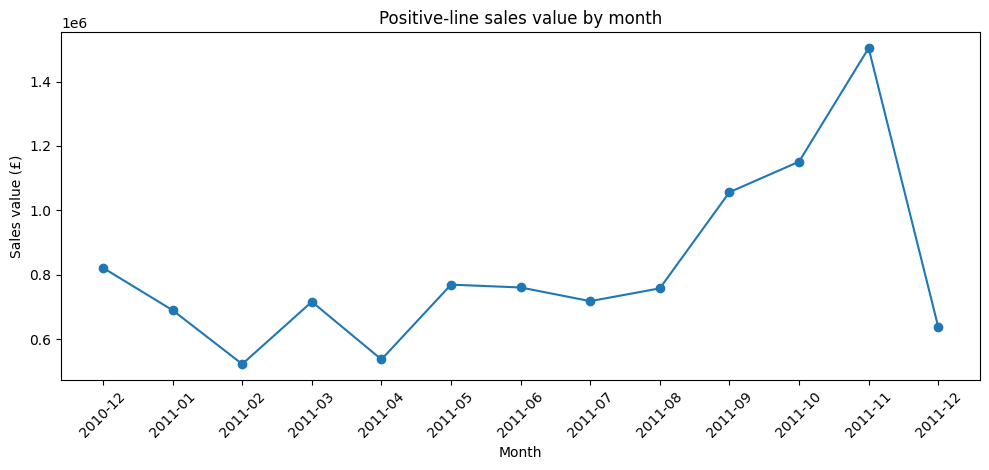

In [27]:
monthly_sales = (
    clean.groupby("Month", as_index=False)
    .agg(
        Positive_line_sales_value=("LineValue", "sum"),
        Units_sold=("Quantity", "sum"),
        Invoice_count=("InvoiceNo", "nunique")
    )
    .sort_values("Month")
)
display(monthly_sales.round(2))

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(monthly_sales["Month"], monthly_sales["Positive_line_sales_value"], marker="o")
ax.set_title("Positive-line sales value by month")
ax.set_xlabel("Month")
ax.set_ylabel("Sales value (£)")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## 9. Business question 2 — which products matter most?

For the product ranking, I exclude descriptions containing `POSTAGE` and rows described as `Manual`, because these are service or manual-entry lines rather than ordinary merchandise. The monthly and country summaries above still include valid positive transaction lines, so their totals answer a slightly broader question.


In [28]:
def most_common_description(values):
    modes = values.mode(dropna=True)
    return modes.iloc[0] if not modes.empty else values.iloc[0]

# Exclude service/manual-entry lines from the merchandise ranking, using only needed columns.
is_service_line = clean["Description"].str.contains(r"POSTAGE|^MANUAL$", case=False, na=False)
product_lines = clean.loc[~is_service_line, ["StockCode", "Description", "Quantity", "InvoiceNo", "LineValue"]]
product_summary = (
    product_lines.groupby("StockCode", as_index=False)
    .agg(
        Description=("Description", most_common_description),
        Units_sold=("Quantity", "sum"),
        Positive_line_sales_value=("LineValue", "sum"),
        Invoice_count=("InvoiceNo", "nunique")
    )
)
print("Product-ranking rows excluded as postage/manual-entry lines:", int(is_service_line.sum()))
del product_lines, is_service_line

top_products_by_value = product_summary.sort_values(
    "Positive_line_sales_value", ascending=False
).head(10)
top_products_by_invoices = product_summary.sort_values(
    "Invoice_count", ascending=False
).head(10)

print("Top 10 merchandise items by positive-line sales value")
display(top_products_by_value.round(2))

print("Top 10 merchandise items by number of invoices")
display(top_products_by_invoices[["StockCode", "Description", "Invoice_count", "Units_sold"]])


Product-ranking rows excluded as postage/manual-entry lines: 2149
Top 10 merchandise items by positive-line sales value


,StockCode,Description,Units_sold,Positive_line_sales_value,Invoice_count
1310,22423,REGENCY CAKESTAND 3 TIER,13851,174156.54,1988
2465,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
3407,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37641,104462.75,2198
2670,47566,PARTY BUNTING,18283,99445.23,1685
3387,85099B,JUMBO BAG RED RETROSPOT,48371,94159.81,2089
2020,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,247
1942,23084,RABBIT NIGHT LIGHT,30739,66870.03,994
1006,22086,PAPER CHAIN KIT 50'S CHRISTMAS,19329,64875.59,1160
3194,84879,ASSORTED COLOUR BIRD ORNAMENT,36362,58927.62,1455
2845,79321,CHILLI LIGHTS,10302,54096.36,661


Top 10 merchandise items by number of invoices


,StockCode,Description,Invoice_count,Units_sold
3407,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2198,37641
3387,85099B,JUMBO BAG RED RETROSPOT,2089,48371
1310,22423,REGENCY CAKESTAND 3 TIER,1988,13851
2670,47566,PARTY BUNTING,1685,18283
175,20725,LUNCH BAG RED RETROSPOT,1565,19432
3194,84879,ASSORTED COLOUR BIRD ORNAMENT,1455,36362
1109,22197,POPCORN HOLDER,1392,56898
1593,22720,SET OF 3 CAKE TINS PANTRY DESIGN,1385,7483
439,21212,PACK OF 72 RETROSPOT CAKE CASES,1320,36396
1276,22383,LUNCH BAG SUKI DESIGN,1284,12518


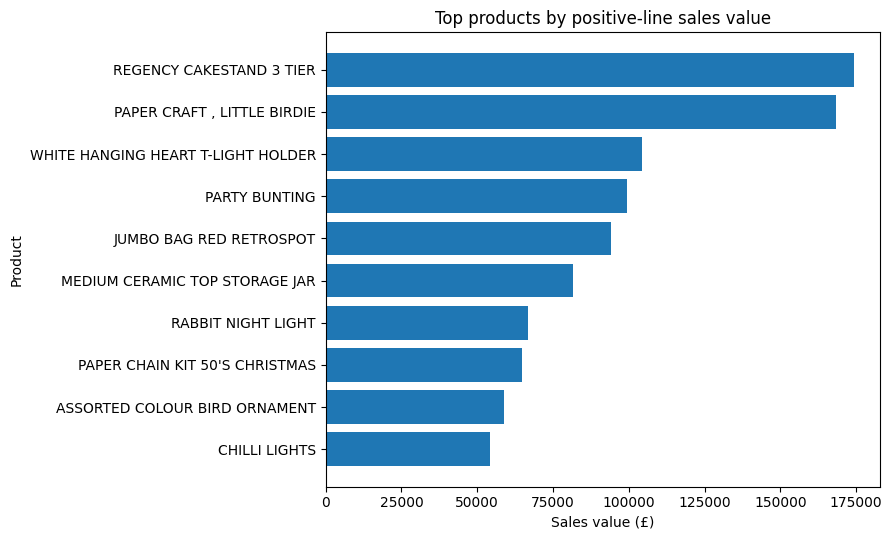

In [29]:
plot_products = top_products_by_value.sort_values("Positive_line_sales_value")
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(plot_products["Description"].astype(str), plot_products["Positive_line_sales_value"])
ax.set_title("Top products by positive-line sales value")
ax.set_xlabel("Sales value (£)")
ax.set_ylabel("Product")
plt.tight_layout()
plt.show()

## 10. Business question 3 — which countries contribute the most?

,Country,Positive_line_sales_value,Invoice_count,Units_sold
36,United Kingdom,9001744.09,18019,4646906
24,Netherlands,285446.34,94,200361
10,EIRE,283140.52,288,147007
14,Germany,228678.40,457,119154
13,France,209625.37,392,112060
0,Australia,138453.81,57,83891
31,Spain,61558.56,90,27933
33,Switzerland,57067.60,54,30617
3,Belgium,41196.34,98,23237
32,Sweden,38367.83,36,36078


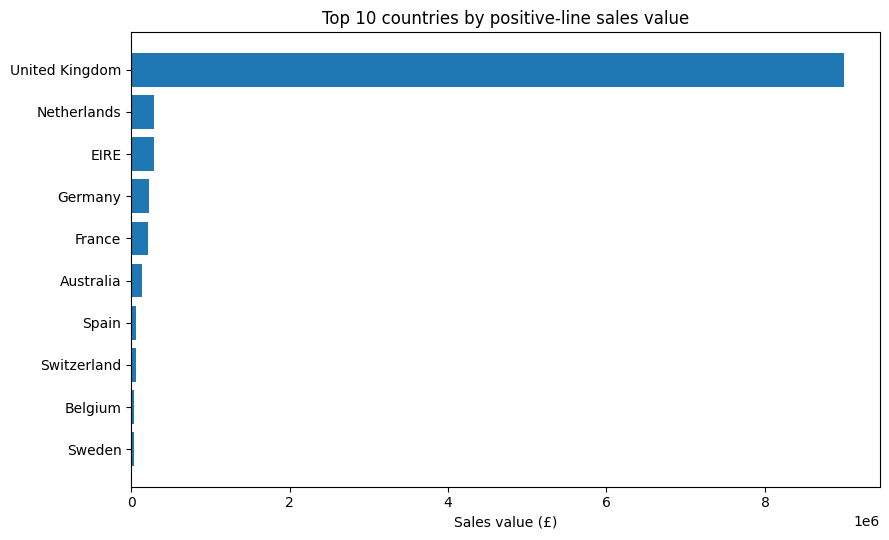

In [30]:
country_summary = (
    clean.groupby("Country", as_index=False)
    .agg(
        Positive_line_sales_value=("LineValue", "sum"),
        Invoice_count=("InvoiceNo", "nunique"),
        Units_sold=("Quantity", "sum")
    )
    .sort_values("Positive_line_sales_value", ascending=False)
)

display(country_summary.head(10).round(2))

plot_countries = country_summary.head(10).sort_values("Positive_line_sales_value")
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(plot_countries["Country"], plot_countries["Positive_line_sales_value"])
ax.set_title("Top 10 countries by positive-line sales value")
ax.set_xlabel("Sales value (£)")
plt.tight_layout()
plt.show()

## 11. Business question 4 — which products appear together?

For the first basket analysis, I am focusing on UK invoices and the 25 most frequently invoiced products. This keeps the matrix small enough to run in Colab and makes the first set of rules easier to explain.

I exclude rows whose description contains `POSTAGE` from basket analysis because postage is a service charge rather than a merchandise item. These rows remain in the sales summaries above. The basket is built at invoice level: a product is marked as present if it appears at least once on an invoice.

I will report:
- **Support:** share of UK invoices containing both products.
- **Confidence:** share of invoices with the first product that also contain the second.
- **Lift:** how much more often the pair appears together than expected if the products occurred independently. Lift above 1 indicates a positive association in this data, not proof of causation.

In [31]:
# Build the UK basket table from only the three columns needed. This lowers memory use.
uk_mask = clean["Country"].str.lower().eq("united kingdom")
not_postage = ~clean["Description"].str.contains("POSTAGE", case=False, na=False)
uk_basket_lines = clean.loc[uk_mask & not_postage, ["InvoiceNo", "StockCode", "Description"]].copy()
del uk_mask, not_postage

uk_invoice_ids = uk_basket_lines["InvoiceNo"].drop_duplicates()
uk_item_frequency = (
    uk_basket_lines.groupby("StockCode", as_index=False)
    .agg(
        Description=("Description", most_common_description),
        Invoice_count=("InvoiceNo", "nunique")
    )
    .sort_values("Invoice_count", ascending=False)
)

TOP_N_ITEMS = 25
top_items = uk_item_frequency.head(TOP_N_ITEMS).copy()
top_item_codes = top_items["StockCode"].tolist()
item_name_map = dict(zip(top_items["StockCode"], top_items["Description"]))

print("UK invoice count used as basket denominator:", len(uk_invoice_ids))
print("Number of products in basket analysis:", len(top_item_codes))
display(top_items.head(10))


UK invoice count used as basket denominator: 17979
Number of products in basket analysis: 25


,StockCode,Description,Invoice_count
3402,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2104
3382,85099B,JUMBO BAG RED RETROSPOT,1935
1308,22423,REGENCY CAKESTAND 3 TIER,1685
2668,47566,PARTY BUNTING,1593
174,20725,LUNCH BAG RED RETROSPOT,1392
3190,84879,ASSORTED COLOUR BIRD ORNAMENT,1371
1107,22197,POPCORN HOLDER,1296
1591,22720,SET OF 3 CAKE TINS PANTRY DESIGN,1241
1341,22457,NATURAL SLATE HEART CHALKBOARD,1219
176,20727,LUNCH BAG BLACK SKULL.,1216


In [32]:
selected_item_lines = uk_basket_lines.loc[
    uk_basket_lines["StockCode"].isin(top_item_codes),
    ["InvoiceNo", "StockCode"]
]

# One row per UK invoice; one column per selected product.
basket_matrix = pd.crosstab(
    selected_item_lines["InvoiceNo"],
    selected_item_lines["StockCode"]
).gt(0)

# Add invoices that do not contain any of the selected top products.
# This keeps support calculated over all eligible UK invoice baskets.
basket_matrix = basket_matrix.reindex(
    index=uk_invoice_ids,
    columns=top_item_codes,
    fill_value=False
).fillna(False).astype(bool)

print("Basket matrix shape:", basket_matrix.shape)
print("Total UK baskets in denominator:", len(basket_matrix))
display(basket_matrix.head())

Basket matrix shape: (17979, 25)
Total UK baskets in denominator: 17979


StockCode,85123A,85099B,22423,47566,20725,84879,22197,22720,22457,20727,22383,22469,22386,22411,23203,21931,21212,22086,82482,20728,23298,22382,22666,22961,22384
InvoiceNo,,,,,,,,,,,,,,,,,,,,,,,,,
536365,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
536366,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
536367,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
536368,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
536369,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


## 12. Calculate pairwise association rules

In [33]:
# These thresholds are project settings, not universal retail standards.
MIN_SUPPORT = 0.003       # pair must appear in at least 0.3% of all UK invoice baskets
MIN_CONFIDENCE = 0.15     # at least 15% of baskets containing A also contain B
MIN_LIFT = 1.0            # keep positive associations above independence

item_support = basket_matrix.mean(axis=0)
candidate_rules = []

codes = basket_matrix.columns.tolist()
for i, item_a in enumerate(codes):
    for item_b in codes[i + 1:]:
        pair_support = float((basket_matrix[item_a] & basket_matrix[item_b]).mean())
        if pair_support == 0:
            continue

        support_a = float(item_support[item_a])
        support_b = float(item_support[item_b])

        if support_a > 0 and support_b > 0:
            confidence_a_to_b = pair_support / support_a
            lift_a_to_b = confidence_a_to_b / support_b
            candidate_rules.append({
                "Antecedent code": item_a,
                "Consequent code": item_b,
                "Antecedent": item_name_map.get(item_a, str(item_a)),
                "Consequent": item_name_map.get(item_b, str(item_b)),
                "Support": pair_support,
                "Confidence": confidence_a_to_b,
                "Lift": lift_a_to_b
            })

            confidence_b_to_a = pair_support / support_b
            lift_b_to_a = confidence_b_to_a / support_a
            candidate_rules.append({
                "Antecedent code": item_b,
                "Consequent code": item_a,
                "Antecedent": item_name_map.get(item_b, str(item_b)),
                "Consequent": item_name_map.get(item_a, str(item_a)),
                "Support": pair_support,
                "Confidence": confidence_b_to_a,
                "Lift": lift_b_to_a
            })

all_rules = pd.DataFrame(candidate_rules)
if all_rules.empty:
    all_rules = pd.DataFrame(columns=[
        "Antecedent code", "Consequent code", "Antecedent", "Consequent",
        "Support", "Confidence", "Lift"
    ])

rules = all_rules.loc[
    (all_rules["Support"] >= MIN_SUPPORT)
    & (all_rules["Confidence"] >= MIN_CONFIDENCE)
    & (all_rules["Lift"] > MIN_LIFT)
].sort_values(["Lift", "Support"], ascending=False).reset_index(drop=True)

print("Directional candidate rules calculated:", len(all_rules))
print("Rules meeting the chosen thresholds:", len(rules))
if rules.empty:
    print("No rules meet all three thresholds in this run. I will not invent any rules.")
else:
    display(rules.head(15).round(4))

Directional candidate rules calculated: 600
Rules meeting the chosen thresholds: 344


,Antecedent code,Consequent code,Antecedent,Consequent,Support,Confidence,Lift
0,20728,22384,LUNCH BAG CARS BLUE,LUNCH BAG PINK POLKADOT,0.0261,0.4413,7.8871
1,22384,20728,LUNCH BAG PINK POLKADOT,LUNCH BAG CARS BLUE,0.0261,0.4672,7.8871
2,20727,22384,LUNCH BAG BLACK SKULL.,LUNCH BAG PINK POLKADOT,0.0290,0.4293,7.6719
3,22384,20727,LUNCH BAG PINK POLKADOT,LUNCH BAG BLACK SKULL.,0.0290,0.5189,7.6719
4,20728,22382,LUNCH BAG CARS BLUE,LUNCH BAG SPACEBOY DESIGN,0.0253,0.4263,7.3837
5,22382,20728,LUNCH BAG SPACEBOY DESIGN,LUNCH BAG CARS BLUE,0.0253,0.4374,7.3837
6,22411,21931,JUMBO SHOPPER VINTAGE RED PAISLEY,JUMBO STORAGE BAG SUKI,0.0285,0.4528,7.2040
7,21931,22411,JUMBO STORAGE BAG SUKI,JUMBO SHOPPER VINTAGE RED PAISLEY,0.0285,0.4540,7.2040
8,22383,22382,LUNCH BAG SUKI DESIGN,LUNCH BAG SPACEBOY DESIGN,0.0274,0.4108,7.1160
9,22382,22383,LUNCH BAG SPACEBOY DESIGN,LUNCH BAG SUKI DESIGN,0.0274,0.4750,7.1160


### Threshold check

Association rules can change when thresholds change. I will compare the number of rules under a few reasonable settings, rather than pretending that one threshold is the only correct choice. A higher lift from a very rare pair should still be interpreted carefully, so I report support and confidence with lift.

In [34]:
threshold_sensitivity = []
for support_threshold, confidence_threshold in [
    (0.003, 0.15),
    (0.005, 0.15),
    (0.003, 0.20),
    (0.005, 0.20)
]:
    if all_rules.empty:
        rule_count = 0
    else:
        rule_count = int((
            (all_rules["Support"] >= support_threshold)
            & (all_rules["Confidence"] >= confidence_threshold)
            & (all_rules["Lift"] > 1.0)
        ).sum())
    threshold_sensitivity.append({
        "Minimum support": support_threshold,
        "Minimum confidence": confidence_threshold,
        "Minimum lift": 1.0,
        "Rules returned": rule_count
    })

display(pd.DataFrame(threshold_sensitivity))

,Minimum support,Minimum confidence,Minimum lift,Rules returned
0,0.003,0.15,1.0,344
1,0.005,0.15,1.0,344
2,0.003,0.20,1.0,168
3,0.005,0.20,1.0,168


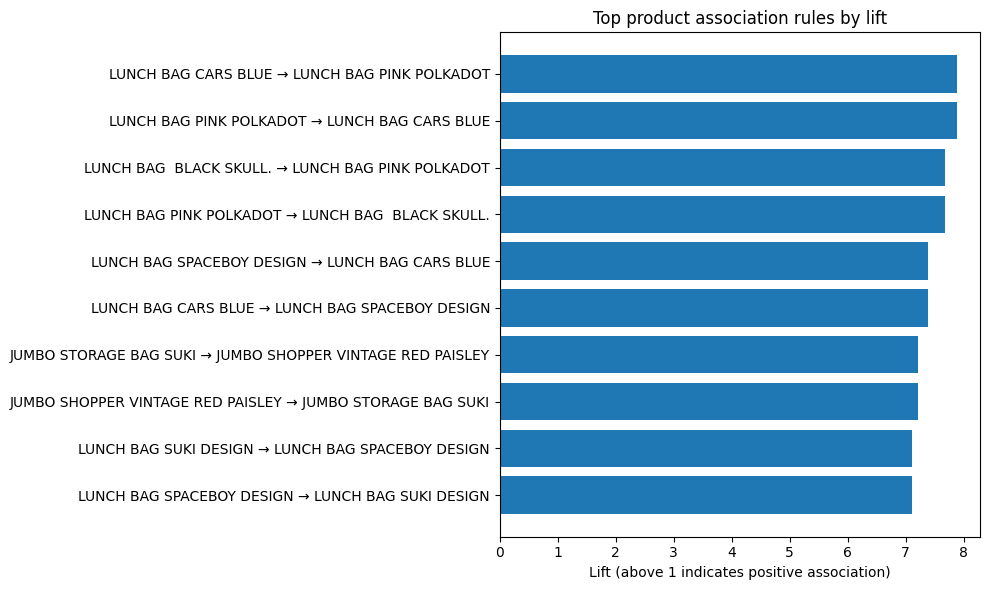

In [35]:
if not rules.empty:
    top_rules = rules.head(10).sort_values("Lift")
    rule_labels = top_rules["Antecedent"].astype(str) + " → " + top_rules["Consequent"].astype(str)

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(rule_labels, top_rules["Lift"])
    ax.set_title("Top product association rules by lift")
    ax.set_xlabel("Lift (above 1 indicates positive association)")
    plt.tight_layout()
    plt.show()
else:
    print("No association chart is drawn because no rules passed the selected thresholds.")

## 13. Turn the results into careful business notes

In [36]:
print("BUSINESS NOTES FROM THIS RUN")
print("-----------------------------")

if not monthly_sales.empty:
    peak_month = monthly_sales.loc[monthly_sales["Positive_line_sales_value"].idxmax()]
    print(
        f"Highest positive-line sales value month: {peak_month['Month']} "
        f"(£{peak_month['Positive_line_sales_value']:,.2f})."
    )

if not top_products_by_value.empty:
    best_product = top_products_by_value.iloc[0]
    print(
        f"Highest positive-line sales value product in this cleaned data: "
        f"{best_product['Description']} (StockCode {best_product['StockCode']}; "
        f"£{best_product['Positive_line_sales_value']:,.2f})."
    )

if not country_summary.empty:
    leading_country = country_summary.iloc[0]
    print(
        f"Country with highest positive-line sales value: {leading_country['Country']} "
        f"(£{leading_country['Positive_line_sales_value']:,.2f})."
    )

if not rules.empty:
    leading_rule = rules.iloc[0]
    print(
        "Highest-lift rule among those meeting the chosen thresholds: "
        f"{leading_rule['Antecedent']} → {leading_rule['Consequent']} "
        f"(support {leading_rule['Support']:.3%}, "
        f"confidence {leading_rule['Confidence']:.1%}, lift {leading_rule['Lift']:.2f})."
    )
else:
    print("No basket rule met the current support, confidence and lift thresholds.")

print("\nThese are patterns in the observed dataset, not proof of causes or guarantees of future demand.")

BUSINESS NOTES FROM THIS RUN
-----------------------------
Highest positive-line sales value month: 2011-11 (£1,503,866.78).
Highest positive-line sales value product in this cleaned data: REGENCY CAKESTAND 3 TIER (StockCode 22423; £174,156.54).
Country with highest positive-line sales value: United Kingdom (£9,001,744.09).
Highest-lift rule among those meeting the chosen thresholds: LUNCH BAG CARS BLUE → LUNCH BAG PINK POLKADOT (support 2.614%, confidence 44.1%, lift 7.89).

These are patterns in the observed dataset, not proof of causes or guarantees of future demand.


## 14. Decisions I made and why

In [37]:
decision_log = pd.DataFrame([
    ["Keep raw data unchanged", "I clean a separate copy so the original rows remain available for checking."],
    ["Remove exact duplicate rows", "Exact repeated lines can double-count sales if left in the analysis."],
    ["Exclude cancellations and non-positive quantities", "The main sales-value charts describe positive sale lines, not returns or reversals."],
    ["Keep rows with missing CustomerID when other required fields are valid", "Invoice-level product and basket analysis does not require a customer ID."],
    ["Flag large values rather than automatically delete them", "Large orders may be genuine wholesale orders; removing them without checking could distort sales."],
    ["Use top 25 products for basket analysis", "This keeps the first association matrix manageable and readable; less frequent products are not covered by these rules."],
    ["Exclude postage/manual lines from product rankings and baskets", "These are service or manual-entry lines, not ordinary merchandise; they remain in monthly and country transaction-line totals."],
    ["Use support, confidence and lift together", "A rule should not be called useful based on lift alone, especially when support is low."]
], columns=["Decision", "Reason / trade-off"])

display(decision_log)

,Decision,Reason / trade-off
0,Keep raw data unchanged,I clean a separate copy so the original rows r...
1,Remove exact duplicate rows,Exact repeated lines can double-count sales if...
2,Exclude cancellations and non-positive quantities,The main sales-value charts describe positive ...
3,Keep rows with missing CustomerID when other r...,Invoice-level product and basket analysis does...
4,Flag large values rather than automatically de...,Large orders may be genuine wholesale orders; ...
5,Use top 25 products for basket analysis,This keeps the first association matrix manage...
6,Exclude postage/manual lines from product rank...,"These are service or manual-entry lines, not o..."
7,"Use support, confidence and lift together",A rule should not be called useful based on li...


## 15. Final quality checks

In [38]:
# Data-quality checks
assert set(required_columns).issubset(raw.columns), "Required source columns are missing."
assert len(clean) > 0, "No rows remain after cleaning."
assert clean["InvoiceNo"].notna().all(), "Clean data contains missing invoice numbers."
assert clean["StockCode"].notna().all(), "Clean data contains missing product codes."
assert clean["Description"].notna().all(), "Clean data contains missing descriptions."
assert clean["InvoiceDate"].notna().all(), "Clean data contains invalid dates."
assert (clean["Quantity"] > 0).all(), "Clean data contains non-positive quantities."
assert (clean["UnitPrice"] > 0).all(), "Clean data contains non-positive unit prices."
assert not clean.duplicated().any(), "Exact duplicate rows remain after cleaning."
assert np.isfinite(clean["Quantity"]).all(), "Quantity contains non-finite values."
assert np.isfinite(clean["UnitPrice"]).all(), "Unit price contains non-finite values."
assert clean["LineValue"].notna().all(), "Line values contain missing values."
assert np.isfinite(clean["LineValue"]).all(), "Line values contain non-finite values."
assert (clean["LineValue"] > 0).all(), "Positive-line sales value contains non-positive values."

# Output checks
assert not monthly_sales.empty, "Monthly sales table is empty."
assert not product_summary.empty, "Product summary is empty."
assert product_summary["StockCode"].is_unique, "Product summary has duplicate product codes."
assert top_items["StockCode"].is_unique, "Top-item table has duplicate product codes."
assert not country_summary.empty, "Country summary is empty."
assert len(basket_matrix) == len(uk_invoice_ids), "Basket denominator does not match UK invoices."
assert basket_matrix.dtypes.astype(str).eq("bool").all(), "Basket matrix is not boolean."
if not all_rules.empty:
    assert all_rules["Support"].between(0, 1).all(), "Support must be between 0 and 1."
    assert all_rules["Confidence"].between(0, 1).all(), "Confidence must be between 0 and 1."
    assert (all_rules["Lift"] >= 0).all(), "Lift must not be negative."
if not rules.empty:
    assert (rules["Support"] >= MIN_SUPPORT).all(), "A rule does not meet minimum support."
    assert (rules["Confidence"] >= MIN_CONFIDENCE).all(), "A rule does not meet minimum confidence."
    assert (rules["Lift"] > MIN_LIFT).all(), "A rule does not meet minimum lift."

# Cleaning step counts must flow sequentially.
assert (cleaning_report["Rows after"] <= cleaning_report["Rows before"]).all(), "A cleaning step increased row count."
assert cleaning_report["Rows after"].iloc[-1] == len(clean), "Cleaning log does not match cleaned data."

print("Raw rows:", len(raw))
print("Cleaned rows:", len(clean))
print("UK baskets analysed:", len(basket_matrix))
print("Association rules returned:", len(rules))
print("PASS: All final validation checks passed.")

Raw rows: 541909
Cleaned rows: 524878
UK baskets analysed: 17979
Association rules returned: 344
PASS: All final validation checks passed.


## 16. Limitations and Recommendations

### Limitations

1. The dataset contains transactions from one online retailer for about one year. Therefore, the results may not represent the buying behaviour of customers in other stores or in later years.

2. The sales values in this analysis are based on positive transaction lines. They should not be treated as final net revenue or profit because returns, operating costs and other business expenses are not fully considered.

3. Some records have missing CustomerID values. I kept these records when the invoice and product details were available because they are still useful for product and invoice-level analysis. However, this limits the customer-level analysis.

4. The basket analysis focuses on UK invoices and the 25 most frequently invoiced products. This makes the analysis easier to manage, but combinations involving less frequent products may be missed.

5. Products appearing together in an invoice do not necessarily mean that one product causes customers to buy the other. The identified associations need further checking before they are used for business decisions.

### Recommendations

1. **Test product bundles:** The retailer can select a few strong product associations from the basket analysis and test them as product bundles or cross-selling suggestions. The retailer should compare the results with normal sales before deciding whether to continue.

2. **Improve stock planning:** Monthly sales patterns and product rankings can help the retailer identify products that deserve closer stock monitoring. However, stock levels should also be decided using current inventory, supplier lead time and more recent demand.

3. **Study customer behaviour:** In future analysis, records with available CustomerID values can be used to study repeat purchases and customer buying patterns. This may help the retailer understand which products are purchased by returning customers.

4. **Check the results on newer data:** The same analysis should be repeated on a more recent dataset. This will help check whether the sales patterns and product associations are still present.

5. **Measure the impact before making changes:** Any new bundle, cross-selling suggestion or stock-planning change should first be tested on a small scale. The retailer can compare sales value, units sold and the number of invoices before and after the change.

### My Conclusion

This project helped me understand how transaction data can be cleaned and analysed to find useful sales patterns and product associations. I would use these findings as a starting point for further investigation rather than making business decisions from one dataset alone. Testing the recommendations on newer data would help check whether they are useful in practice.

## 17. Dataset Reference and Reproducibility

### Dataset Reference

Chen, D. (2015). *Online Retail*. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33

Dataset page: https://archive.ics.uci.edu/dataset/352/online%2Bretail

License: CC BY 4.0.

### Reproducibility

The notebook contains the steps used to load the dataset, check data quality, clean the transaction records, perform exploratory data analysis and analyse product associations. The tables and plots show the results generated from the dataset. The validation checks are included to help confirm that the main analysis steps have worked correctly.